# Sampling k from N

The problem is how to sample k options from N, given logits for each of the N options. This is a common problem in reinforcement learning when we want to sample multiple actions from a categorical distribution, or in combinatorial optimisation when we want to sample subsets of items.

In [178]:
from collections.abc import Callable

import torch

In [179]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Setup

We set up random logits for a batch of B instances, with R rollouts per each, and N options to choose from. We will sample k options from these N for each rollout.

In [180]:
B, R, N = 64, 128, 20
k = 5

logits = torch.rand(B, R, N)
print(logits[0, 0])

tensor([0.3512, 0.8571, 0.4740, 0.8915, 0.4045, 0.2648, 0.9760, 0.2947, 0.1302,
        0.3096, 0.1145, 0.6577, 0.2540, 0.4304, 0.8032, 0.7084, 0.8783, 0.4845,
        0.5273, 0.7663])


In [181]:
N_SAMPLES = 50_000

single_logits = logits[0, 0]  # (N,) - fixed instance for analysis
repeated_logits = single_logits.unsqueeze(0).expand(N_SAMPLES, -1)  # (N_SAMPLES, N)

## Sampling

### Categorical

In [182]:
distribution = torch.distributions.Categorical(logits=logits)
selected = distribution.sample()
print(selected.shape)
print(selected[0, 0])
print(selected[0, 1])

torch.Size([64, 128])
tensor(12)
tensor(2)


### Multinomial without replacement

In [183]:
selected = torch.multinomial(logits.softmax(-1).view(-1, N), num_samples=k, replacement=False).view(
    B, R, k
)
print(selected.shape)
print(selected[0, 0])
print(selected[0, 1])

torch.Size([64, 128, 5])
tensor([17, 19, 16,  7,  5])
tensor([ 9,  6, 14, 16,  2])


### Gumbel

**Variant 1**

In [184]:
gumbel = -torch.log(-torch.log(torch.rand_like(logits) + 1e-10))
print(gumbel.shape)
print(gumbel[0, 0])

selected = (logits + gumbel).topk(k, dim=-1).indices  # (B, R, k)
print(selected.shape)
print(selected[0, 0])
print(selected[0, 1])

torch.Size([64, 128, 20])
tensor([ 2.6744, -0.0901,  0.1447, -0.5507, -0.4978,  2.6641,  0.2722, -0.4569,
         1.2703,  0.3976,  0.6577,  2.3565, -0.4561, -0.1243,  2.2638,  1.2372,
        -1.4492,  1.3184,  0.2376,  0.6705])
torch.Size([64, 128, 5])
tensor([14,  0, 11,  5, 15])
tensor([16,  6, 19,  5, 10])


**Variant 2**

In [185]:
m = torch.distributions.gumbel.Gumbel(torch.zeros_like(logits), torch.ones_like(logits))
gumbel = m.sample()

selected = (logits + gumbel).topk(k, dim=-1).indices  # (B, R, k)
print(selected.shape)
print(selected[0, 0])
print(selected[0, 1])

torch.Size([64, 128, 5])
tensor([19, 14,  6, 13, 15])
tensor([ 9, 17, 16,  4,  8])


## Log-probability from subsequent sampled actions

Log-probability is required for REINFORCE. It needs to be differentiable w.r.t. the logits. However, it doesn't to be differentiable w.r.t. the selected indices.

In [186]:
import torch.nn.functional as F


def plackett_luce_log_p(logits: torch.Tensor, selected: torch.Tensor) -> torch.Tensor:
    # logits: (B, R, N), selected: (B, R, k)
    B, R, N = logits.shape
    k = selected.shape[-1]
    log_p = torch.zeros(B, R, device=logits.device)
    mask = torch.zeros(B, R, N, dtype=torch.bool, device=logits.device)

    for t in range(k):
        masked_logits = logits.masked_fill(mask, float("-inf"))
        log_p += (
            F.log_softmax(masked_logits, dim=-1).gather(-1, selected[..., t : t + 1]).squeeze(-1)
        )
        mask = mask.scatter(-1, selected[..., t : t + 1], True)

    return log_p  # (B, R)


log_p = plackett_luce_log_p(logits, selected)
print(log_p.shape)  # (B, R)
print(log_p[0, 0])
print(torch.exp(log_p[0, 0]))

torch.Size([64, 128])
tensor(-13.4128)
tensor(1.4959e-06)


## Sampling functions

In [187]:
def sample_gumbel_topk(
    logits: torch.Tensor, k: int, generator: torch.Generator | None = None
) -> torch.Tensor:
    u = torch.rand(logits.shape, generator=generator)
    gumbel = -torch.log(-torch.log(u.clamp(min=1e-10)))
    return (logits + gumbel).topk(k, dim=-1).indices


def sample_gumbel_distributions(
    logits: torch.Tensor, k: int, generator: torch.Generator | None = None
) -> torch.Tensor:
    gumbel = torch.distributions.Gumbel(torch.zeros_like(logits), torch.ones_like(logits)).sample()
    return (logits + gumbel).topk(k, dim=-1).indices


def sample_multinomial_softmax(
    logits: torch.Tensor, k: int, generator: torch.Generator | None = None
) -> torch.Tensor:
    probs = logits.softmax(dim=-1)
    flat = probs.view(-1, logits.shape[-1])
    selected = torch.multinomial(flat, num_samples=k, replacement=False, generator=generator)
    return selected.view(*logits.shape[:-1], k)


def sample_multinomial_raw(
    logits: torch.Tensor, k: int, generator: torch.Generator | None = None
) -> torch.Tensor:
    flat = logits.view(-1, logits.shape[-1])
    selected = torch.multinomial(flat, num_samples=k, replacement=False, generator=generator)
    return selected.view(*logits.shape[:-1], k)

In [188]:
def sample_k_slots(
    logits: torch.Tensor,
    k: int,
    generator: torch.Generator | None = None,
) -> torch.Tensor:
    """Sample k nodes using k independent slot queries over shared logits.

    Each slot independently samples one node by adding its own Gumbel noise,
    simulating k learned query vectors attending to the same node embeddings.
    Unlike Gumbel-top-k, slots sample with replacement - duplicates can occur.

    Args:
        logits: (..., N) shared base logits.
        k: number of slots.
        generator: optional RNG for reproducibility.

    Returns:
        (..., k) selected indices, one per slot. May contain duplicates.
    """
    # (..., N) -> (..., k, N): each slot gets its own independent Gumbel noise
    slot_logits = logits.unsqueeze(-2).expand(*logits.shape[:-1], k, logits.shape[-1])
    u = torch.rand(slot_logits.shape, generator=generator)
    gumbel = -torch.log(-torch.log(u.clamp(min=1e-10)))
    return (slot_logits + gumbel).argmax(dim=-1)  # (..., k)


def selection_stats(selected: torch.Tensor) -> dict:
    """Compute duplicate statistics over a batch of selections.

    Args:
        selected: (n_samples, k) selected indices.

    Returns:
        Dict with:
            duplicate_rate: fraction of samples with at least one duplicate.
            mean_duplicates: average number of duplicate entries per sample (k - num_unique).
            duplicate_ratio: mean_duplicates / k - fraction of slots wasted to duplicates.
    """
    k = selected.shape[-1]
    num_unique = torch.tensor([selected[i].unique().shape[0] for i in range(selected.shape[0])])
    num_duplicates = k - num_unique
    return {
        "duplicate_rate": (num_duplicates > 0).float().mean().item(),
        "mean_duplicates": num_duplicates.float().mean().item(),
        "duplicate_ratio": (num_duplicates.float() / k).mean().item(),
    }


g = torch.Generator().manual_seed(0)
slots_selected = sample_k_slots(repeated_logits, k, generator=g)
gumbel_selected = sample_gumbel_topk(repeated_logits, k, generator=g)

slots_stats = selection_stats(slots_selected)
gumbel_stats = selection_stats(gumbel_selected)

print(f"{'':30s} {'k-slots':>10} {'Gumbel-top-k':>14}")
print(
    f"{'Duplicate rate':30s} {slots_stats['duplicate_rate']:>10.3f} {gumbel_stats['duplicate_rate']:>14.3f}"
)
print(
    f"{'Mean duplicates (out of k={k})':30s} {slots_stats['mean_duplicates']:>10.3f} {gumbel_stats['mean_duplicates']:>14.3f}"
)
print(
    f"{'Duplicate ratio':30s} {slots_stats['duplicate_ratio']:>10.3f} {gumbel_stats['duplicate_ratio']:>14.3f}"
)

                                  k-slots   Gumbel-top-k
Duplicate rate                      0.434          0.000
Mean duplicates (out of k={k})      0.497          0.000
Duplicate ratio                     0.099          0.000


## Marginal distributions

For each method, we estimate the marginal selection probability P(node i is selected) empirically
over many samples from a single fixed instance. Gumbel-top-k and multinomial-softmax should converge
to the same marginals (both sample from Plackett-Luce), while multinomial-raw will differ since it
treats logit values directly as weights rather than log-probabilities.

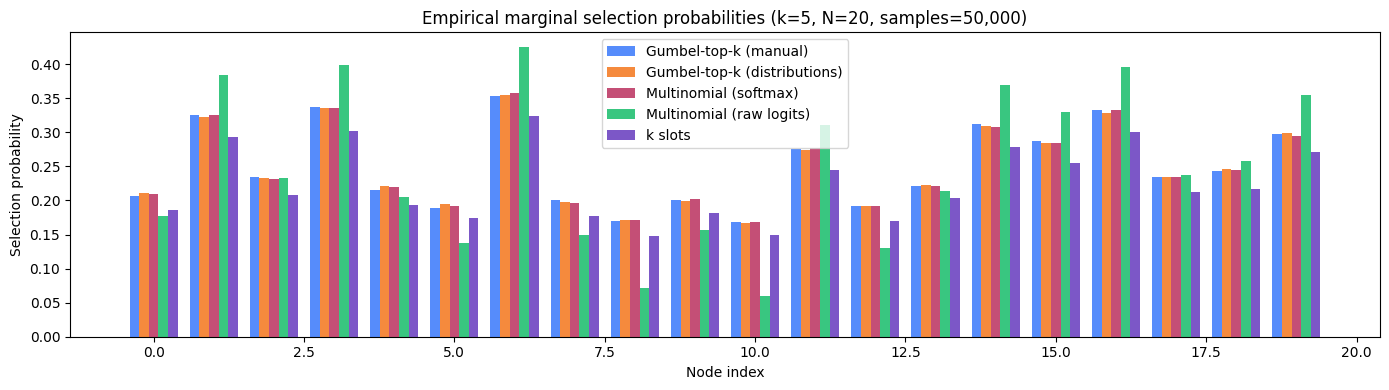

In [189]:
import matplotlib.pyplot as plt


def empirical_marginals(logits_2d: torch.Tensor, sample_fn: Callable, k: int) -> torch.Tensor:
    """Estimate marginal selection probability for each node via Monte Carlo.

    Args:
        logits_2d: (n_samples, N) logits repeated across sample dimension.
        sample_fn: callable(logits, k) -> (n_samples, k) selected indices.
        k: number of items selected per sample.

    Returns:
        (N,) empirical selection probabilities, one per node.
    """
    N = logits_2d.shape[-1]
    n_samples = logits_2d.shape[0]
    selected = sample_fn(logits_2d, k)  # (n_samples, k)
    counts = torch.zeros(N)
    for i in range(N):
        counts[i] = (selected == i).any(dim=-1).float().sum()
    return counts / n_samples


methods = [
    ("Gumbel-top-k (manual)", sample_gumbel_topk),
    ("Gumbel-top-k (distributions)", sample_gumbel_distributions),
    ("Multinomial (softmax)", sample_multinomial_softmax),
    ("Multinomial (raw logits)", sample_multinomial_raw),
    ("k slots", sample_k_slots),
]

marginals = {name: empirical_marginals(repeated_logits, fn, k) for name, fn in methods}

fig, ax = plt.subplots(figsize=(14, 4))
x = torch.arange(N)
width = 0.8 / len(methods)
offsets = torch.linspace(
    -width * (len(methods) - 1) / 2, width * (len(methods) - 1) / 2, len(methods)
)

for (name, _), offset in zip(methods, offsets):
    ax.bar(x + offset, marginals[name], width, label=name)

ax.set_xlabel("Node index")
ax.set_ylabel("Selection probability")
ax.set_title(f"Empirical marginal selection probabilities (k={k}, N={N}, samples={N_SAMPLES:,})")
ax.legend()
plt.tight_layout()
plt.show()